# 01 - Analyse exploratoire des données (EDA)

## Projet : Détection des fraudes dans les transactions Mobile Money avec PaySim

### Objectif

Ce notebook a pour objectif d'explorer les données du projet afin de comprendre leur structure, leur qualité et leurs caractéristiques avant leur utilisation dans les modèles de Machine Learning.

Les données sont récupérées directement depuis le Data Warehouse PostgreSQL hébergé sur Render.

### Analyses réalisées

- Exploration générale des données.
- Vérification de leur qualité.
- Analyse de la distribution des transactions frauduleuses et normales.
- Étude des types d'opérations et des montants.
- Analyse temporelle des transactions.
- Étude du mécanisme de signalement existant.
- Vérification de l'échantillonnage du Data Warehouse.

### Problématique

Comment repérer automatiquement les transactions frauduleuses sans bloquer les clients honnêtes ?

### Variable cible

`is_fraud` :
- 0 : transaction normale.
- 1 : transaction frauduleuse.

### Précautions

Les variables `oldbalanceOrg`, `newbalanceOrig`, `oldbalanceDest` et `newbalanceDest` sont interdites comme variables explicatives conformément aux consignes du professeur.

La variable `is_flagged_fraud` sera étudiée, mais exclue des variables explicatives de notre premier modèle.

In [23]:
# Manipulation des données
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Connexion PostgreSQL
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

# Gestion des chemins et variables d'environnement
from pathlib import Path
import os

# Métriques pour analyser le mécanisme de signalement existant
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


## 2. Connexion au Data Warehouse PostgreSQL

Le Data Warehouse est hébergé sur Render et utilise PostgreSQL.

Nous allons établir une connexion directe depuis Python en utilisant les informations stockées dans le fichier `.env`, situé à la racine du projet.

La connexion sera utilisée uniquement pour lire les données. Aucune modification des tables ne sera effectuée.

In [24]:
# Recherche de la racine du projet
PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / ".env").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError("Fichier .env introuvable.")

# Chargement des informations de connexion
load_dotenv(PROJECT_ROOT / ".env")

DATABASE_URL = os.getenv("DATABASE_URL")

if not DATABASE_URL:
    raise ValueError("DATABASE_URL est absente du fichier .env.")

DATABASE_URL = DATABASE_URL.replace("postgres://", "postgresql://", 1)

# Connexion PostgreSQL
engine = create_engine(
    DATABASE_URL,
    connect_args={"sslmode": "require"},
    pool_pre_ping=True
)

with engine.connect() as connection:
    version = connection.execute(text("SELECT version()")).scalar()

print("Connexion PostgreSQL réussie.")
print("Version :", version)

Connexion PostgreSQL réussie.
Version : PostgreSQL 18.7 (Debian 18.7-1.pgdg12+5) on x86_64-pc-linux-gnu, compiled by gcc (Debian 12.2.0-14+deb12u1) 12.2.0, 64-bit


## 3. Extraction des données

Nous récupérons les transactions depuis la table de faits `fact_transactions`, en utilisant les jointures avec les dimensions temporelle, opérationnelle et des comptes.

Cette opération permet de réunir les informations nécessaires à notre analyse dans un seul DataFrame Pandas.

In [25]:
query = """
SELECT
    f.transaction_id,
    t.step,
    t.jour,
    t.heure,
    t.tranche_horaire,
    t.type_jour,
    op.code_type AS type_operation,
    op.categorie AS categorie_operation,
    f.amount,
    em.account_type AS type_compte_emetteur,
    dest.account_type AS type_compte_destinataire,
    f.is_fraud,
    f.is_flagged_fraud

FROM fact_transactions f

INNER JOIN dim_temps t
    ON f.time_id = t.time_id

INNER JOIN dim_type_operation op
    ON f.type_id = op.type_id

INNER JOIN dim_compte_emetteur em
    ON f.orig_account_id = em.orig_account_id

INNER JOIN dim_compte_destinataire dest
    ON f.dest_account_id = dest.dest_account_id
"""

df = pd.read_sql_query(query, engine)

print(f"Extraction terminée : {len(df):,} transactions récupérées.")

display(df.head())

Extraction terminée : 299,983 transactions récupérées.


,transaction_id,step,jour,heure,tranche_horaire,type_jour,type_operation,categorie_operation,amount,type_compte_emetteur,type_compte_destinataire,is_fraud,is_flagged_fraud
0,23,130,6,9,Matin,Week-end,CASH_OUT,Retrait,"179,718.53",Client,Client,0,0
1,109,16,1,15,Après-midi,Semaine,CASH_OUT,Retrait,"243,534.61",Client,Client,0,0
2,132,347,15,10,Matin,Semaine,CASH_IN,Dépôt,"293,881.02",Client,Client,0,0
3,163,275,12,10,Matin,Semaine,CASH_OUT,Retrait,"114,762.09",Client,Client,0,0
4,168,34,2,9,Matin,Semaine,PAYMENT,Achat,"62,175.13",Client,Commerçant,0,0


## 4. Exploration générale et qualité des données

Nous examinons la structure du jeu de données et vérifions sa qualité.

Cette étape permet notamment de détecter les valeurs manquantes, les doublons et les éventuelles incohérences avant de poursuivre les analyses.

In [26]:
# Dimensions et informations générales
print("DIMENSIONS :", df.shape)
print("\nTYPES DE DONNÉES :")
print(df.dtypes)

print("\nSTATISTIQUES DESCRIPTIVES :")
display(df.describe(include="all").T)

# Vérification de la qualité
quality_report = pd.DataFrame({
    "Valeurs manquantes": df.isnull().sum(),
    "Pourcentage manquant (%)": df.isnull().mean() * 100
})

display(quality_report)

print("Transactions dupliquées :",
      df["transaction_id"].duplicated().sum())

print("Montants nuls ou négatifs :",
      (df["amount"] <= 0).sum())

print("Valeurs incorrectes de is_fraud :",
      (~df["is_fraud"].isin([0, 1])).sum())

DIMENSIONS : (299983, 13)

TYPES DE DONNÉES :
transaction_id                int64
step                          int64
jour                          int64
heure                         int64
tranche_horaire              object
type_jour                    object
type_operation               object
categorie_operation          object
amount                      float64
type_compte_emetteur         object
type_compte_destinataire     object
is_fraud                      int64
is_flagged_fraud              int64
dtype: object

STATISTIQUES DESCRIPTIVES :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,"299,983.00",NaN,NaN,NaN,"149,994.00","86,597.78",3.00,"74,998.50","149,994.00","224,989.50","299,985.00"
step,"299,983.00",NaN,NaN,NaN,246.61,146.27,1.00,156.00,249.00,346.00,743.00
jour,"299,983.00",NaN,NaN,NaN,10.63,6.09,1.00,7.00,11.00,15.00,31.00
heure,"299,983.00",NaN,NaN,NaN,14.51,4.22,0.00,11.00,15.00,18.00,23.00
tranche_horaire,299983,4,Après-midi,130197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_jour,299983,2,Semaine,217644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type_operation,299983,5,CASH_OUT,106654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categorie_operation,299983,5,Retrait,106654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,"299,983.00",NaN,NaN,NaN,"213,759.41","727,335.57",0.23,"13,736.63","79,202.27","216,653.34","60,642,003.00"
type_compte_emetteur,299983,1,Client,299983,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Valeurs manquantes,Pourcentage manquant (%)
transaction_id,0,0.00
step,0,0.00
jour,0,0.00
heure,0,0.00
tranche_horaire,0,0.00
type_jour,0,0.00
type_operation,0,0.00
categorie_operation,0,0.00
amount,0,0.00
type_compte_emetteur,0,0.00


Transactions dupliquées : 0
Montants nuls ou négatifs : 0
Valeurs incorrectes de is_fraud : 0


## 5. Analyse de la variable cible : is_fraud

Nous étudions la répartition des transactions normales et frauduleuses.

Cette analyse permet de mesurer le déséquilibre des classes, un élément important dans la construction d'un modèle de détection des fraudes.

,Nombre de transactions,Pourcentage (%)
Normales,291786,97.27
Frauduleuses,8197,2.73


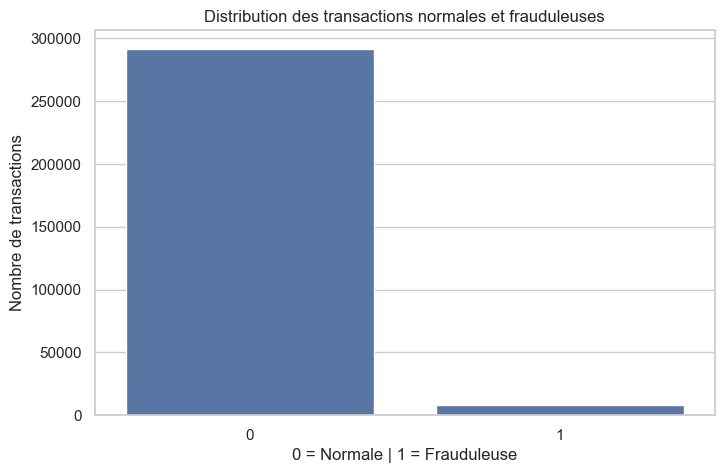

Taux de fraude : 2.73 %


In [27]:
# Distribution des classes
class_distribution = df["is_fraud"].value_counts().sort_index()

class_summary = pd.DataFrame({
    "Nombre de transactions": class_distribution,
    "Pourcentage (%)": df["is_fraud"].value_counts(
        normalize=True
    ).sort_index() * 100
})

class_summary.index = ["Normales", "Frauduleuses"]

display(class_summary)

# Visualisation
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="is_fraud")

plt.title("Distribution des transactions normales et frauduleuses")
plt.xlabel("0 = Normale | 1 = Frauduleuse")
plt.ylabel("Nombre de transactions")

plt.show()

print(f"Taux de fraude : {df['is_fraud'].mean() * 100:.2f} %")

## 6. Analyse des types d'opérations

PaySim comprend cinq types d'opérations : CASH-IN, CASH-OUT, DEBIT, PAYMENT et TRANSFER.

Nous allons étudier leur répartition et déterminer quelles catégories présentent les taux de fraude les plus élevés.

,nombre_transactions,nombre_fraudes,taux_fraude (%)
type_operation,,,
TRANSFER,28379,4097,14.44
CASH_OUT,106654,4100,3.84
CASH_IN,64253,0,0.00
DEBIT,1903,0,0.00
PAYMENT,98794,0,0.00


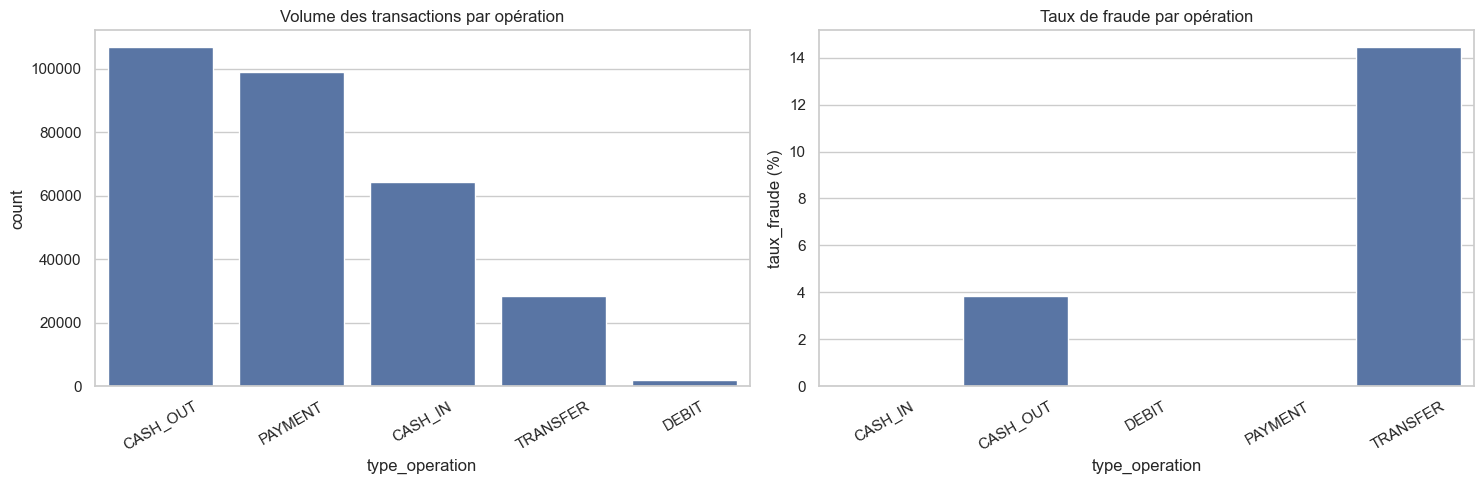

In [28]:
# Analyse des opérations
operation_analysis = (
    df.groupby("type_operation")
    .agg(
        nombre_transactions=("is_fraud", "count"),
        nombre_fraudes=("is_fraud", "sum")
    )
)

operation_analysis["taux_fraude (%)"] = (
    operation_analysis["nombre_fraudes"]
    / operation_analysis["nombre_transactions"]
) * 100

display(operation_analysis.sort_values(
    "taux_fraude (%)", ascending=False
))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(
    data=df,
    x="type_operation",
    order=df["type_operation"].value_counts().index,
    ax=axes[0]
)

axes[0].set_title("Volume des transactions par opération")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=operation_analysis.reset_index(),
    x="type_operation",
    y="taux_fraude (%)",
    ax=axes[1]
)

axes[1].set_title("Taux de fraude par opération")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 7. Analyse des montants des transactions

Nous étudions la distribution des montants et les différences entre les transactions normales et frauduleuses.

Cette analyse permettra d'identifier d'éventuelles particularités dans les montants associés aux transactions frauduleuses.

Une échelle logarithmique sera utilisée pour faciliter la visualisation des montants très dispersés.

,count,mean,median,min,max
Normales,291786,"178,445.07","75,028.45",0.23,"60,642,003.00"
Frauduleuses,8197,"1,470,832.67","442,290.23",63.80,"10,000,000.00"


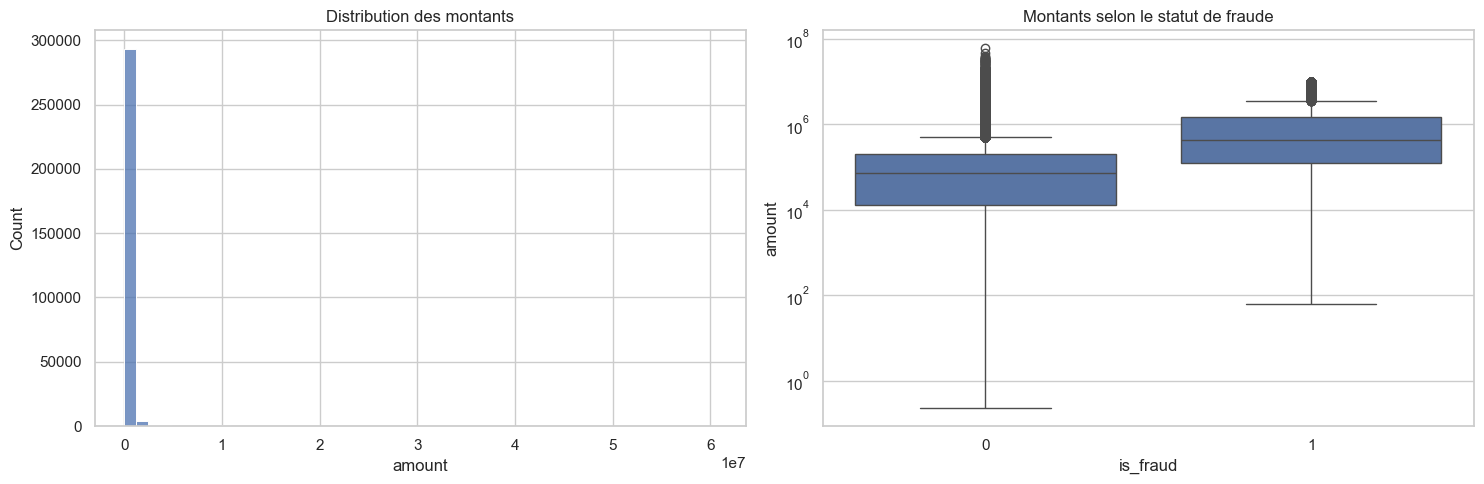

In [29]:
# Statistiques des montants selon la classe
amount_analysis = (
    df.groupby("is_fraud")["amount"]
    .agg(["count", "mean", "median", "min", "max"])
)

amount_analysis.index = ["Normales", "Frauduleuses"]

display(amount_analysis)

# Visualisations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df,
    x="amount",
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Distribution des montants")

sns.boxplot(
    data=df,
    x="is_fraud",
    y="amount",
    ax=axes[1]
)

axes[1].set_yscale("log")
axes[1].set_title("Montants selon le statut de fraude")

plt.tight_layout()
plt.show()

## 8. Analyse temporelle des transactions

La variable `step` représente une période horaire dans PaySim.

Nous allons examiner l'évolution du volume des transactions et du nombre de fraudes dans le temps.

Cette analyse sera également utile pour préparer une séparation chronologique des données lors du prétraitement.

Nombre de périodes : 743
Première période : 1
Dernière période : 743
Périodes sans fraude : 2


,nombre_transactions,nombre_fraudes,taux_fraude (%)
step,,,
1,148,16,10.81
2,56,8,14.29
3,35,4,11.43
4,42,10,23.81
5,38,6,15.79


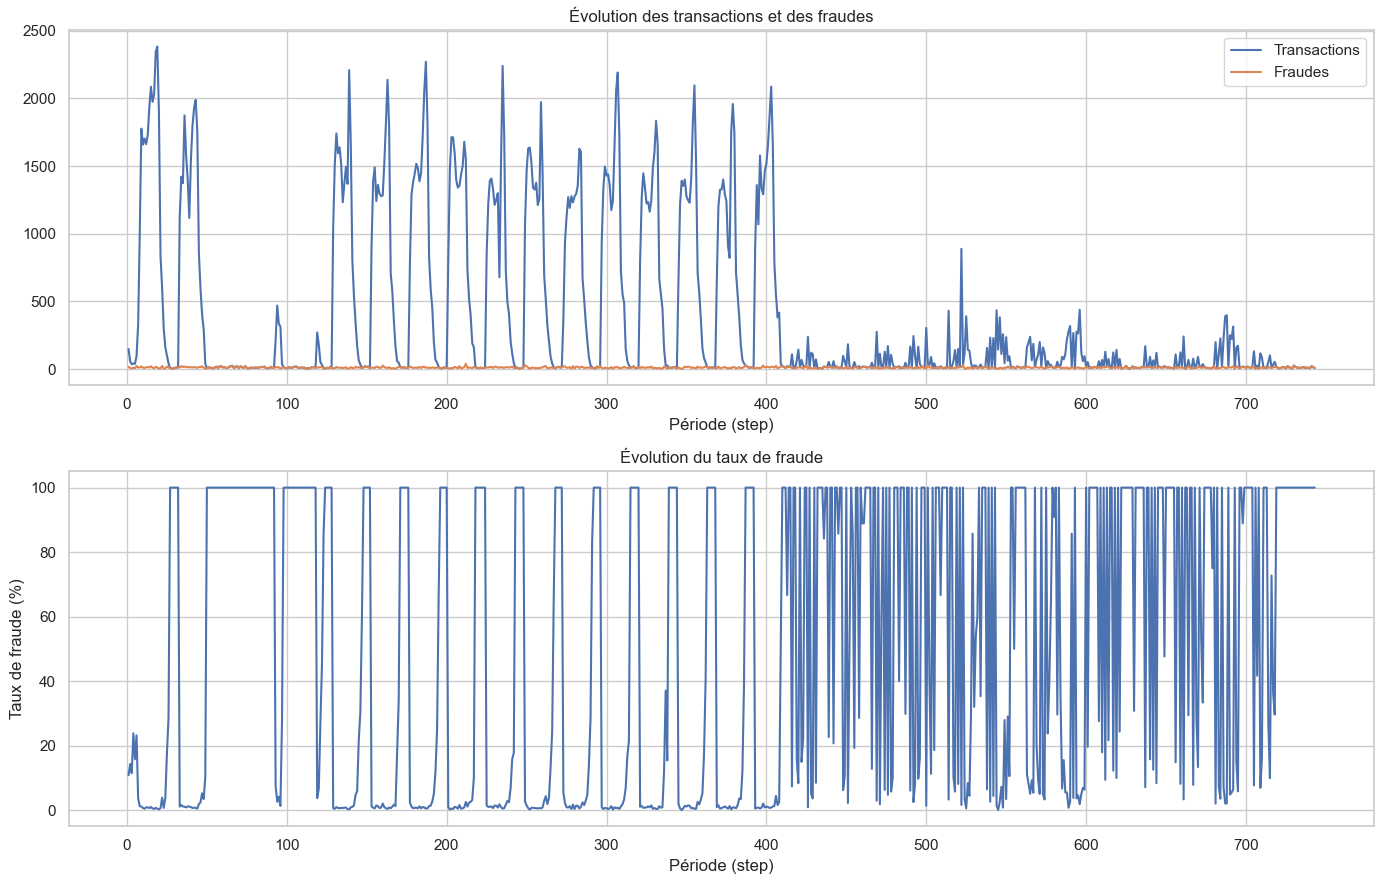

In [30]:
# Agrégation par période
temporal_analysis = (
    df.groupby("step")
    .agg(
        nombre_transactions=("is_fraud", "count"),
        nombre_fraudes=("is_fraud", "sum")
    )
)

temporal_analysis["taux_fraude (%)"] = (
    temporal_analysis["nombre_fraudes"]
    / temporal_analysis["nombre_transactions"]
) * 100

print("Nombre de périodes :", len(temporal_analysis))
print("Première période :", temporal_analysis.index.min())
print("Dernière période :", temporal_analysis.index.max())
print("Périodes sans fraude :",
      (temporal_analysis["nombre_fraudes"] == 0).sum())

display(temporal_analysis.head())

# Visualisations temporelles
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(
    temporal_analysis.index,
    temporal_analysis["nombre_transactions"],
    label="Transactions"
)

axes[0].plot(
    temporal_analysis.index,
    temporal_analysis["nombre_fraudes"],
    label="Fraudes"
)

axes[0].set_title("Évolution des transactions et des fraudes")
axes[0].set_xlabel("Période (step)")
axes[0].legend()

axes[1].plot(
    temporal_analysis.index,
    temporal_analysis["taux_fraude (%)"]
)

axes[1].set_title("Évolution du taux de fraude")
axes[1].set_xlabel("Période (step)")
axes[1].set_ylabel("Taux de fraude (%)")

plt.tight_layout()
plt.show()

## 9. Analyse de is_flagged_fraud

La variable `is_flagged_fraud` indique si une transaction a été signalée par le mécanisme existant dans PaySim.

Nous allons la comparer à la véritable classe `is_fraud` afin d'évaluer les performances de ce mécanisme.

Cette variable sera utilisée uniquement comme référence comparative et non comme variable explicative de notre premier modèle.

In [31]:
# Comparaison entre les fraudes réelles et signalées
display(pd.crosstab(
    df["is_fraud"],
    df["is_flagged_fraud"],
    rownames=["Fraude réelle"],
    colnames=["Fraude signalée"],
    margins=True
))

# Évaluation du mécanisme existant
y_true = df["is_fraud"]
y_pred = df["is_flagged_fraud"]

print("Matrice de confusion :")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nPrecision :", precision_score(
    y_true, y_pred, zero_division=0
))

print("Recall :", recall_score(
    y_true, y_pred, zero_division=0
))

print("F1-score :", f1_score(
    y_true, y_pred, zero_division=0
))

Fraude signalée,0,1,All
Fraude réelle,,,
0,291786,0,291786
1,8181,16,8197
All,299967,16,299983


Matrice de confusion :
[[291786      0]
 [  8181     16]]

Precision : 1.0
Recall : 0.0019519336342564352
F1-score : 0.0038962620236210883


## 10. Vérification de l'échantillonnage du Data Warehouse

Le Data Warehouse contient un échantillon du dataset PaySim original.

Lors de la constitution du DWH, les transactions frauduleuses ont été sélectionnées avant que les transactions légitimes soient échantillonnées par type d'opération.

Nous allons comparer les deux sources afin de mesurer les conséquences de cet échantillonnage.

Cette vérification est importante pour comprendre la représentativité des données et interpréter correctement les futures métriques du modèle.

In [32]:
# Emplacement du dataset original
RAW_DATA_PATH = PROJECT_ROOT / "data" / "paysim.csv"

if not RAW_DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset original introuvable : {RAW_DATA_PATH}\n"
        "Vérifie son emplacement ou adapte RAW_DATA_PATH."
    )

# Comptage du dataset original par morceaux
original_counts = {}
original_total = 0

for chunk in pd.read_csv(
    RAW_DATA_PATH,
    usecols=["type", "amount", "isFraud"],
    chunksize=500_000
):
    original_total += len(chunk)

    grouped = chunk.groupby(["type", "isFraud"]).size()

    for key, value in grouped.items():
        original_counts[key] = (
            original_counts.get(key, 0) + int(value)
        )

# Comptage du DWH
dwh_counts = (
    df.groupby(["type_operation", "is_fraud"])
    .size()
)

# Construction du tableau comparatif
comparison = []

for (operation, fraud_status), original_count in original_counts.items():

    dwh_count = dwh_counts.get(
        (operation, fraud_status), 0
    )

    comparison.append({
        "Opération": operation,
        "Classe": "Frauduleuse" if fraud_status == 1 else "Normale",
        "Nombre original": original_count,
        "Nombre DWH": dwh_count,
        "Taux de conservation (%)": (
            dwh_count / original_count * 100
            if original_count > 0 else 0
        )
    })

sampling_comparison = pd.DataFrame(comparison)

display(
    sampling_comparison.sort_values(
        ["Opération", "Classe"]
    )
)

# Comparaison globale des classes
original_frauds = sum(
    value for (operation, fraud), value in original_counts.items()
    if fraud == 1
)

original_legitimate = sum(
    value for (operation, fraud), value in original_counts.items()
    if fraud == 0
)

dwh_frauds = int(df["is_fraud"].sum())
dwh_legitimate = int((df["is_fraud"] == 0).sum())

global_comparison = pd.DataFrame({
    "Dataset original": [original_legitimate, original_frauds],
    "Data Warehouse": [dwh_legitimate, dwh_frauds]
}, index=["Transactions normales", "Transactions frauduleuses"])

global_comparison["Conservation (%)"] = (
    global_comparison["Data Warehouse"]
    / global_comparison["Dataset original"]
) * 100

display(global_comparison)

print(f"Volume original : {original_total:,}")
print(f"Volume DWH : {len(df):,}")
print(f"Taux de fraude original : {original_frauds / original_total * 100:.4f} %")
print(f"Taux de fraude DWH : {df['is_fraud'].mean() * 100:.4f} %")

,Opération,Classe,Nombre original,Nombre DWH,Taux de conservation (%)
0,CASH_IN,Normale,1399284,64253,4.59
2,CASH_OUT,Frauduleuse,4116,4100,99.61
1,CASH_OUT,Normale,2233384,102554,4.59
3,DEBIT,Normale,41432,1903,4.59
4,PAYMENT,Normale,2151495,98794,4.59
6,TRANSFER,Frauduleuse,4097,4097,100.00
5,TRANSFER,Normale,528812,24282,4.59


,Dataset original,Data Warehouse,Conservation (%)
Transactions normales,6354407,291786,4.59
Transactions frauduleuses,8213,8197,99.81


Volume original : 6,362,620
Volume DWH : 299,983
Taux de fraude original : 0.1291 %
Taux de fraude DWH : 2.7325 %


## 11. Synthèse de l'analyse exploratoire

Cette section présente les principaux enseignements de l'analyse.

Les résultats obtenus permettront de mieux comprendre :

- La qualité et la structure des données.
- Le déséquilibre entre les classes.
- Les types d'opérations présentant le plus de fraudes.
- Les caractéristiques des montants.
- La répartition temporelle des transactions.
- Les performances du mécanisme de signalement existant.
- Les conséquences de l'échantillonnage du Data Warehouse.

Ces observations serviront de base aux décisions méthodologiques du prochain notebook consacré au prétraitement.

In [33]:
print("========== SYNTHÈSE DE L'EDA ==========")

print(f"\nTransactions analysées : {len(df):,}")
print(f"Nombre de fraudes : {df['is_fraud'].sum():,}")
print(f"Taux de fraude : {df['is_fraud'].mean() * 100:.2f} %")

print("\nTypes d'opérations :")
print(df["type_operation"].value_counts())

print("\nAnalyse temporelle :")
print(f"Nombre de périodes : {df['step'].nunique()}")
print(f"Période minimale : {df['step'].min()}")
print(f"Période maximale : {df['step'].max()}")

print("\nMontants :")
print(f"Moyenne : {df['amount'].mean():,.2f}")
print(f"Médiane : {df['amount'].median():,.2f}")

print("\n========== FIN DE L'EDA ==========")

========== SYNTHÈSE DE L'EDA ==========

Transactions analysées : 299,983
Nombre de fraudes : 8,197
Taux de fraude : 2.73 %

Types d'opérations :
type_operation
CASH_OUT    106654
PAYMENT      98794
CASH_IN      64253
TRANSFER     28379
DEBIT         1903
Name: count, dtype: int64

Analyse temporelle :
Nombre de périodes : 743
Période minimale : 1
Période maximale : 743

Montants :
Moyenne : 213,759.41
Médiane : 79,202.27

========== FIN DE L'EDA ==========


## Conclusion

L'analyse exploratoire a permis d'étudier les principales caractéristiques des transactions contenues dans le Data Warehouse PaySim.

Elle a notamment permis d'examiner la distribution des classes, les types d'opérations, les montants, les comportements temporels et le mécanisme de signalement existant.

La comparaison avec le dataset original permettra de prendre en compte les effets de l'échantillonnage dans les étapes suivantes.

Les résultats de cette analyse serviront à définir les variables à conserver, les transformations nécessaires et la stratégie de séparation des données.

Le prochain notebook sera consacré au prétraitement des données avant l'entraînement des modèles de Machine Learning.